# 05 — Geração de cenários hidrológicos
Objetivo: framework **reproduzível** de cenários para o horizonte **jul–dez** (6 passos mensais, unidades hm³/mês), separando:
- **Família A (`historical_storage`)**: só armazenamento observado (Portal; ANA em cenário separado). Sem afluência, E ou R.
- **Família B (`synthetic`)**: cenários condicionados a **hipóteses** (E, geometria, R). Afluência é **implícita**, nunca observada.

Não há MILP, QUBO ou QAOA aqui. Nenhum resultado valida o balanço hídrico.

In [1]:
import sys, json, hashlib, platform; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data.loaders import load_portal_volume, load_ana_history
from src.hydrology.evaporation import load_power, penman_open_water_mm
from src.scenarios.generator import ScenarioGenerator
from src.scenarios import synthetic as S, temporal as T
from src.scenarios.schema import HORIZON_MONTHS

SEED, N_DRAWS, BLOCK_LEN = 20260101, 50, 3
vol = load_portal_volume('../data/reserv-ors-capac-175236-portal-hidrologico-ce.csv')
ana = load_ana_history('../data/raw/Histórico_ORÓS.xls')
met = load_power('../data/raw/meteo/nasa_power_oros_daily.json'); met['E_mm_day'] = penman_open_water_mm(met)
gen = ScenarioGenerator(vol, met, ana)

## 1. Revisão do experimento 04 antes de gerar cenários
Contribuição de cada fator à variância da mediana de afluência implícita (ago–nov) na grade de 560 combinações (efeitos principais aditivos; fatores **não** independentes: E = escala × área).

In [2]:
g = pd.read_csv('../results/sensitivity_grid.csv')
tot = g.median_dry_hm3_day.var()
share = {f: g.groupby(f).median_dry_hm3_day.transform('mean').var() / tot for f in ['e_scale', 'a_full', 'r_m3s', 'k']}
pd.Series(share, name='fração da variância').round(2).to_frame()

,fração da variância
e_scale,0.41
a_full,0.32
r_m3s,0.21
k,0.05


**Leitura:** escala de E (≈41 %) e área máxima (≈32 %) dominam; R explica ≈21 %; k, ≈5 %. Como E = escala·e·A(V), escala e A_full atuam multiplicativamente e **não são separáveis** com estes dados. Evaporação+geometria somam ≈ 78 % da variância, então a incerteza hidrológica é sobretudo incerteza de **saídas por evaporação**, não de retirada.

Agora, A, B e C são plausíveis como baseline? Teste de **viabilidade física** (não de calibração): quantos meses jul–dez são viáveis (mês completo, não saturado e afluência implícita ≥ 0) em cada configuração?

In [3]:
cfgs = S.DEFAULT_CONFIGS
tab = gen.eligibility(cfgs)
summ = tab.groupby('config').agg(meses=('eligible', 'size'), completos=('complete', 'sum'), viaveis=('eligible', 'sum'),
                                 negativos=('reason', lambda r: (r == 'negative_implied_inflow').sum()))
summ['frac_negativos_entre_completos'] = (summ.negativos / summ.completos).round(2)
summ

,meses,completos,viaveis,negativos,frac_negativos_entre_completos
config,,,,,
A_low,118,108,7,101,0.94
B_mid,118,108,103,5,0.05
C_high,118,108,108,0,0.00


**Decisão:** a configuração **A (E×0,7; A=150 km²; k=0,8; R=2,65)** é inviável em quase todos os meses completos (afluência implícita negativa) — com essas hipóteses ela **contradiz** a queda observada do armazenamento. Mantida no código como configuração provisória, mas **não gera cenários**; não ajustamos seus parâmetros para forçar viabilidade. B e C são viáveis na grande maioria. Isso **não** as torna corretas: ≥ 0 é condição necessária, não evidência. A faixa entre B e C representa a incerteza **sobrevivente**, e foi escolhida por conveniência (grade de 04), não calibrada.

In [4]:
rows = []
for c in cfgs:
    t = tab[tab.config == c.name]
    rows.append(dict(config=c.name, **c.as_dict()))
pd.DataFrame(rows).drop(columns='name').set_index(pd.Series([c.name for c in cfgs]))

,config,a_full,k,e_scale,r_m3s,cap_hm3,v_full,dead_volume_hm3
A_low,A_low,150,0.8,0.7,2.65,1752.36,1940.0,109.78
B_mid,B_mid,200,0.7,1.0,4.50,1752.36,1940.0,109.78
C_high,C_high,250,0.5,1.3,5.30,1752.36,1940.0,109.78


## 2. Família A — armazenamento observado (jul–dez)

In [5]:
hist = gen.generate_historical()
meta_h = pd.DataFrame([s.meta() for s in hist])
print(len(hist), 'cenários |', meta_h.groupby('storage_origin').size().to_dict())
meta_h[['scenario_id', 'initial_storage_hm3', 'n_unusable_months', 'any_saturated', 'any_missing']]

20 cenários | {'ana_observed': 1, 'portal_observed': 19}


,scenario_id,initial_storage_hm3,n_unusable_months,any_saturated,any_missing
0,H_portal_2007,1335.84,0,False,False
1,H_portal_2008,1752.36,1,True,False
2,H_portal_2009,1752.36,2,True,False
3,H_portal_2010,1499.60,1,False,True
4,H_portal_2011,1752.36,2,True,True
5,H_portal_2012,1577.10,0,False,False
6,H_portal_2013,1098.74,2,False,True
7,H_portal_2014,1044.97,0,False,False
8,H_portal_2015,722.90,0,False,False
9,H_portal_2016,557.73,0,False,False


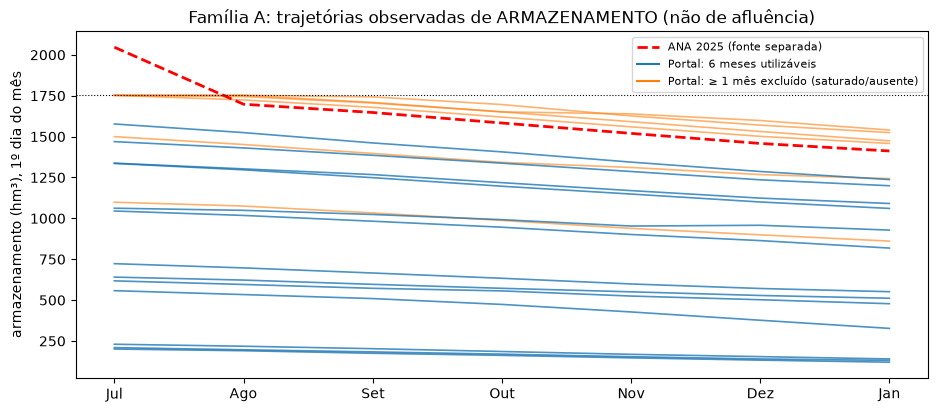

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for s in hist:
    m = s.months; x = list(range(7, 13)) + [13]
    y = list(m.storage_start_hm3) + [m.storage_end_hm3.iloc[-1]]
    if 'ana' in s.scenario_id:
        ax.plot(x, y, 'r--', lw=2, label='ANA 2025 (fonte separada)')
    else:
        ok = m.usable.all()
        ax.plot(x, y, color='C0' if ok else 'C1', alpha=.8 if ok else .6, lw=1.2)
ax.plot([], [], 'C0', label='Portal: 6 meses utilizáveis'); ax.plot([], [], 'C1', label='Portal: ≥ 1 mês excluído (saturado/ausente)')
ax.axhline(1752.36, color='k', ls=':', lw=.8); ax.set_xticks(range(7, 14), ['Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez', 'Jan'])
ax.set_ylabel('armazenamento (hm³), 1º dia do mês'); ax.legend(fontsize=8)
ax.set_title('Família A: trajetórias observadas de ARMAZENAMENTO (não de afluência)')
fig.savefig('../results/figures/05_family_A_storage.png', dpi=150, bbox_inches='tight')

## 3. Família B — cenários sintéticos condicionados a hipóteses

In [7]:
syn, tab = gen.generate_synthetic(cfgs, n_draws=N_DRAWS, seed=SEED, block_len=BLOCK_LEN)
meta_s = pd.DataFrame([s.meta() for s in syn]); meta_s['config'] = meta_s.scenario_id.str.split('_').str[1]
print(len(syn), 'cenários')
meta_s.groupby(['config', 'method']).size().unstack(fill_value=0)

128 cenários


method,conditioned_replay,seasonal_block_bootstrap_L3,stress_driest_block,stress_drought_then_recovery
config,,,,
B,11,50,1,1
C,13,50,1,1


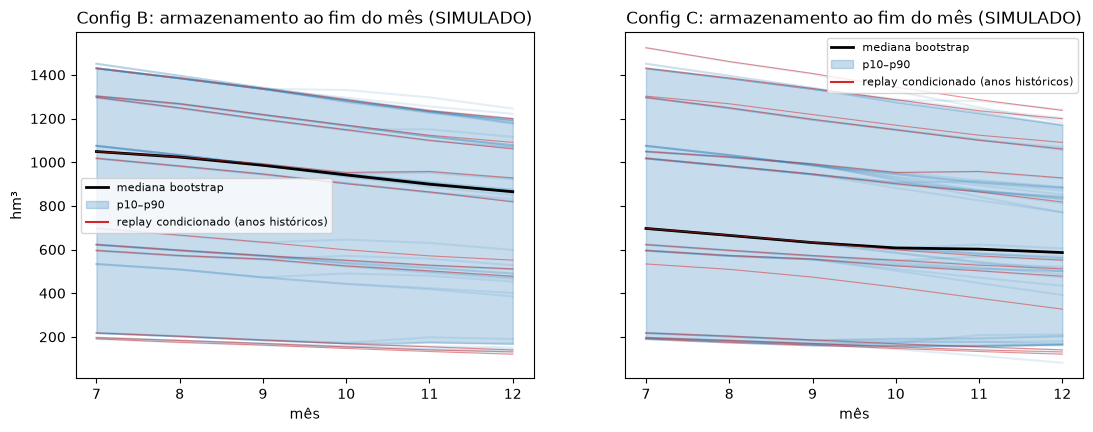

In [8]:
allm = pd.concat([s.months.assign(config=s.scenario_id.split('_')[1], method=s.method) for s in syn], ignore_index=True)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, cn in zip(axs, ['B', 'C']):
    d = allm[(allm.config == cn) & allm.method.str.startswith('seasonal')]
    for sid, g_ in d.groupby('scenario_id'):
        ax.plot(g_.month, g_.storage_end_hm3, color='C0', alpha=.12)
    q = d.groupby('month').storage_end_hm3.quantile([.1, .5, .9]).unstack()
    ax.plot(q.index, q[.5], 'k-', lw=2, label='mediana bootstrap'); ax.fill_between(q.index, q[.1], q[.9], color='C0', alpha=.25, label='p10–p90')
    r = allm[(allm.config == cn) & (allm.method == 'conditioned_replay')]
    for sid, g_ in r.groupby('scenario_id'): ax.plot(g_.month, g_.storage_end_hm3, color='C3', alpha=.5, lw=.8)
    ax.plot([], [], 'C3', label='replay condicionado (anos históricos)'); ax.set_title(f'Config {cn}: armazenamento ao fim do mês (SIMULADO)')
    ax.set_xlabel('mês'); ax.legend(fontsize=8)
axs[0].set_ylabel('hm³'); fig.savefig('../results/figures/05_family_B_storage_fan.png', dpi=150, bbox_inches='tight')

### Disponibilidade mensal
`availability = armazenamento_inicial + afluência_implícita − evaporação` (bruta, **antes** das retiradas, sem volume morto — não é água alocável operacionalmente).

mean           min            50%            max        
config      B      C      B      C       B      C       B       C
month                                                            
7       956.0  809.0  202.0  204.0  1061.0  711.0  1463.0  1538.0
8       923.0  777.0  187.0  188.0  1036.0  679.0  1408.0  1474.0
9       885.0  745.0  173.0  175.0   998.0  646.0  1352.0  1418.0
10      850.0  711.0  163.0  158.0   954.0  622.0  1343.0  1339.0
11      819.0  684.0  150.0  127.0   911.0  616.0  1309.0  1294.0
12      788.0  658.0  137.0   96.0   877.0  600.0  1258.0  1255.0

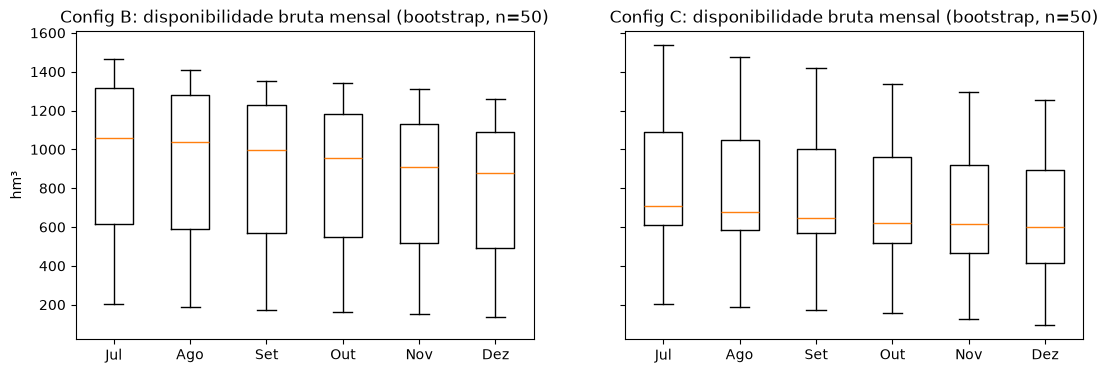

In [9]:
d = allm[allm.method.str.startswith('seasonal')]
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, cn in zip(axs, ['B', 'C']):
    dd = d[d.config == cn]
    ax.boxplot([dd[dd.month == m].availability_hm3 for m in HORIZON_MONTHS], tick_labels=['Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
    ax.set_title(f'Config {cn}: disponibilidade bruta mensal (bootstrap, n={dd.scenario_id.nunique()})')
axs[0].set_ylabel('hm³'); fig.savefig('../results/figures/05_monthly_availability.png', dpi=150, bbox_inches='tight')
d.groupby(['config', 'month']).availability_hm3.describe()[['mean', 'min', '50%', 'max']].round(0).unstack(0)

In [10]:
# Amostra efetiva do bootstrap: quantos sorteios são realmente distintos?
bb = allm[allm.method.str.startswith('seasonal')].drop_duplicates('scenario_id')[['scenario_id', 'config', 'year_or_draw']]
bb['first_block_year'] = bb.year_or_draw.str.split('+').str[0]
print(bb.groupby('config').agg(sorteios=('scenario_id', 'size'), combinacoes_de_blocos_distintas=('year_or_draw', 'nunique'), anos_iniciais_distintos=('first_block_year', 'nunique')))
print('Disponibilidade operacional = max(0, S + I − E − V_morto), V_morto =', S.CONFIG_B.dead_volume_hm3, 'hm³ (hipótese: menor volume já observado no Portal)')
d.groupby('config')[['availability_hm3', 'operational_availability_hm3']].describe().T.round(0).loc[(slice(None), ['mean', 'min', 'max']), :]

        sorteios  combinacoes_de_blocos_distintas  anos_iniciais_distintos
config                                                                    
B             50                               43                       14
C             50                               44                       13
Disponibilidade operacional = max(0, S + I − E − V_morto), V_morto = 109.78 hm³ (hipótese: menor volume já observado no Portal)


config                                  B       C
availability_hm3             mean   870.0   731.0
                             min    137.0    96.0
                             max   1463.0  1538.0
operational_availability_hm3 mean   760.0   621.0
                             min     27.0     0.0
                             max   1353.0  1428.0

**Leitura:** os 50 sorteios correspondem a poucas combinações distintas de anos de origem e a ~11–13 estados iniciais diferentes; **não são 50 observações independentes**. A variabilidade das bandas e boxplots acima é dominada pelo armazenamento inicial. Na otimização (exp. 06) o armazenamento inicial é fator experimental separado e a incerteza vem das sequências de afluência dos anos históricos viáveis, com pesos iguais por ano (suposição).

### Seca e recuperação

,scenario_id,initial_storage_hm3,total_inflow_hm3,notes
61,S_B_mid_stress_drought_2017,230.14,50.709488,Driest eligible Jul–Dec under this config (yea...
62,S_B_mid_stress_recovery_2016_2011,557.73,106.305805,Driest Jul–Sep (2016) among low-storage starts...
126,S_C_high_stress_drought_2016,557.73,146.978087,Driest eligible Jul–Dec under this config (yea...
127,S_C_high_stress_recovery_2019_2011,200.85,286.939338,Driest Jul–Sep (2019) among low-storage starts...


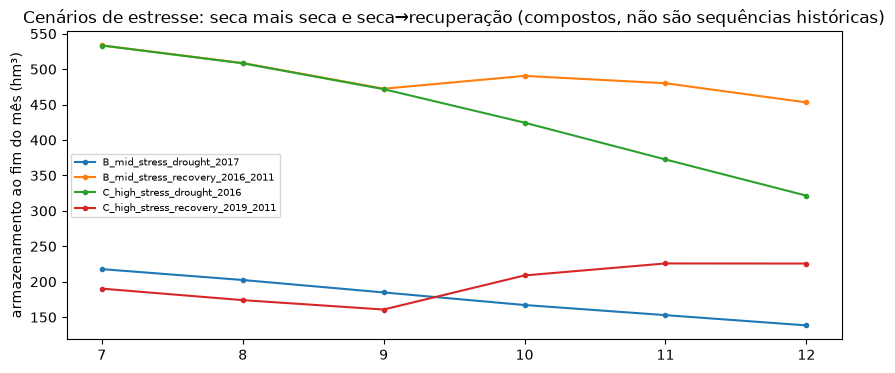

In [11]:
st = allm[allm.method.str.startswith('stress')]
fig, ax = plt.subplots(figsize=(10, 4))
for sid, g_ in st.groupby('scenario_id'):
    ax.plot(g_.month, g_.storage_end_hm3, marker='o', ms=3, label=sid.replace('S_', ''))
ax.set_ylabel('armazenamento ao fim do mês (hm³)'); ax.legend(fontsize=7); ax.set_title('Cenários de estresse: seca mais seca e seca→recuperação (compostos, não são sequências históricas)')
fig.savefig('../results/figures/05_stress_scenarios.png', dpi=150, bbox_inches='tight')
meta_s[meta_s.method.str.startswith('stress')][['scenario_id', 'initial_storage_hm3', 'total_inflow_hm3', 'notes']]  # recuperação parte de armazenamento baixo (tercil inferior)

### Comparação A × B × C e incerteza entre configurações

Anos com 6 meses completos em B e C: 13
Diferença absoluta C−B (hm³): mediana 183 | intervalo 117 – 229
Variação interanual de B (desvio-padrão, hm³): 35


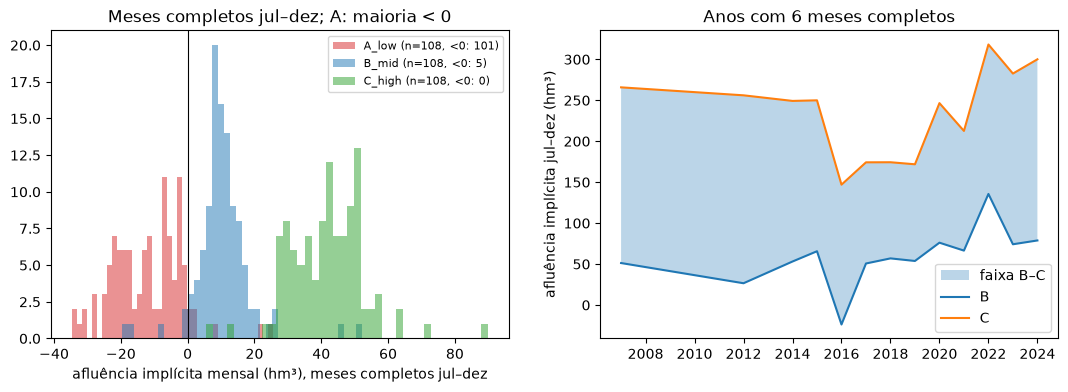

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for c, col in zip(['A_low', 'B_mid', 'C_high'], ['C3', 'C0', 'C2']):
    t = tab[tab.config == c]; t = t[t.complete]
    axs[0].hist(t.I_hm3, bins=40, alpha=.5, label=f'{c} (n={len(t)}, <0: {(t.I_hm3<0).sum()})', color=col)
axs[0].axvline(0, color='k', lw=.8); axs[0].set_xlabel('afluência implícita mensal (hm³), meses completos jul–dez'); axs[0].legend(fontsize=8)
pv = tab[tab.complete].pivot_table(index=['year', 'month'], columns='config', values='I_hm3').dropna()
yr = pv.groupby(level=0).sum(); yr = yr[pv.groupby(level=0).size() == 6]
axs[1].fill_between(yr.index, yr.B_mid, yr.C_high, alpha=.3, label='faixa B–C'); axs[1].plot(yr.index, yr.B_mid, label='B'); axs[1].plot(yr.index, yr.C_high, label='C')
axs[1].set_ylabel('afluência implícita jul–dez (hm³)'); axs[1].legend(); axs[1].set_title('Anos com 6 meses completos')
from matplotlib.ticker import MaxNLocator
axs[1].xaxis.set_major_locator(MaxNLocator(integer=True)); axs[0].set_title('Meses completos jul–dez; A: maioria < 0')
fig.savefig('../results/figures/05_configs_comparison.png', dpi=150, bbox_inches='tight')
print('Anos com 6 meses completos em B e C:', len(yr))
print('Diferença absoluta C−B (hm³): mediana', round((yr.C_high - yr.B_mid).median()), '| intervalo', round((yr.C_high - yr.B_mid).min()), '–', round((yr.C_high - yr.B_mid).max()))
print('Variação interanual de B (desvio-padrão, hm³):', round(yr.B_mid.std()))

**Leitura:** a diferença entre hipóteses B e C (≈ 117–229 hm³ na afluência implícita jul–dez) é **várias vezes maior** que a variabilidade interanual dentro de B (desvio-padrão ≈ 35 hm³). Ou seja, a incerteza das hipóteses de evaporação domina a incerteza que os cenários conseguem representar. Qualquer decisão de alocação sensível a esse intervalo depende das hipóteses, não só do clima histórico. Razões entre C e B não são informativas (denominador próximo de zero em alguns anos).

## 4. Dependência temporal

In [13]:
for c in ['B_mid', 'C_high']:
    t = tab[(tab.config == c) & tab.eligible].pivot(index='year', columns='month', values='I_hm3')
    r_i = T.lag1_autocorr(t)
    dv = tab[(tab.config == c) & tab.complete].pivot(index='year', columns='month', values='dV_hm3')
    r_d = T.lag1_autocorr(dv)
    print(c, '| afluência implícita: r1 =', round(r_i['r_lag1'], 2), 'n_pares =', r_i['n_pairs'], '±', round(r_i['approx_95ci_halfwidth'], 2),
          '| ΔV: r1 =', round(r_d['r_lag1'], 2), 'n =', r_d['n_pairs'])
print('Anos com 6 meses viáveis (B):', len(T.eligible_years(tab[tab.config == 'B_mid'], HORIZON_MONTHS)))

B_mid | afluência implícita: r1 = 0.29 n_pares = 80 ± 0.22 | ΔV: r1 = 0.79 n = 86
C_high | afluência implícita: r1 = 0.76 n_pares = 86 ± 0.21 | ΔV: r1 = 0.79 n = 86
Anos com 6 meses viáveis (B): 11


**Leitura:** com poucos anos viáveis (B: 11; C: 13) e ~80 pares mês-a-mês, a incerteza (± ≈ 0,22) é grande demais para **calibrar** um modelo de dependência temporal. O bootstrap sazonal em blocos de 3 meses preserva a dependência **dentro** de cada bloco (jul–set e out–dez) e **não** a preserva na fronteira set/out. Não se usou bootstrap em blocos móveis sobre o registro contínuo, porque emendaria dezembro com julho de anos diferentes. O r₁ da afluência implícita **depende da hipótese** (≈ 0,29 em B; ≈ 0,76 em C), pois E suaviza a série: parte da dependência é artefato das hipóteses, não propriedade da afluência. Os cenários **não** são previsões calibradas.

## 5. Validação, reprodutibilidade e saídas

In [14]:
errs = gen.validate(hist + syn); print('violações de esquema:', errs or 'nenhuma')
meta, months = ScenarioGenerator.save(hist + syn, tab, '../data/processed/scenarios')
# reprodutibilidade: regenerar com a mesma semente e comparar hashes
syn2, _ = ScenarioGenerator(vol, met, ana).generate_synthetic(cfgs, n_draws=N_DRAWS, seed=SEED, block_len=BLOCK_LEN)
h = lambda ss: hashlib.sha256(ScenarioGenerator.to_tables(ss)[1].to_csv(index=False).encode()).hexdigest()
print('hash igual na regeneração:', h(syn) == h(syn2), h(syn)[:16])
conf = dict(seed=SEED, n_draws=N_DRAWS, block_len=BLOCK_LEN, horizon_months=HORIZON_MONTHS, units='hm3/month',
            configs=[c.as_dict() for c in cfgs], months_hash=h(syn), python=platform.python_version(),
            pandas=pd.__version__, numpy=np.__version__,
            sources=dict(portal='data/reserv-ors-capac-175236-portal-hidrologico-ce.csv', ana='data/raw/Histórico_ORÓS.xls',
                         meteo='data/raw/meteo/nasa_power_oros_daily.json (NASA POWER, grade)'))
json.dump(conf, open('../results/scenario_generation_config.json', 'w'), indent=2, default=str)
print(meta.shape, months.shape); meta.groupby(['family', 'inflow_origin']).size()

violações de esquema: nenhuma


hash igual na regeneração: True f24cc61021efb5e4
(148, 14) (888, 25)


family              inflow_origin         
historical_storage  none                       20
synthetic           implied_from_portal_dV     24
                    resampled_implied         104
dtype: int64

## 6. Limitações não resolvidas
1. Afluência é **implícita** (ΔV + E + R, Z = 0); não foi medida. Dias saturados (≈ 7 %), em geral de maior afluência, são excluídos.
2. A evaporação vem de dados de grade; a geometria A(V) e R são hipóteses; escala de E e área são inseparáveis.
3. A (config baixa) é fisicamente inviável com estes dados; B e C são apenas viáveis, não validadas.
4. Dependência temporal não é calibrável com 11–13 anos viáveis e depende da hipótese de E; blocos sazonais são um compromisso.
5. Meses com afluência implícita negativa são **excluídos** (não ajustados), o que pode enviesar a distribuição para cima.
6. Disponibilidade é bruta e ignora volume morto; cap de armazenamento = nível de saturação do Portal (hipótese).
7. Os cenários **não** são previsões nem validam o balanço hídrico.